In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal

from plot_helpers import plot_signal, plot_emg_vs_joystick, plot_frequencies

In [91]:
df = pd.read_csv("data_for_cleaning.csv")
# tiempo relativo (más fácil de interpretar)
df["t"] = df["t_micros"] * 1e-6

df["emg_ext"] -= df["emg_ext"].mean()
df["emg_flex"] -= df["emg_flex"].mean()

df["y_top"] = -df["y_top"] + 500
df["y_bottom"] = -df["y_bottom"] + 550

df["y"] = df["y_top"] + df["y_bottom"]
df.dropna(inplace=True)

print(len(df))
df.head()

59463


,pc_time,t_micros,y_top,y_bottom,emg_ext,emg_flex,command,block_id,t,y
0,1.779392e+09,8,-21,22,-0.456519,17.67526,rest,1,0.000008,1
1,1.779392e+09,1312,-21,21,2.543481,16.67526,rest,1,0.001312,0
2,1.779392e+09,2696,-21,21,2.543481,16.67526,rest,1,0.002696,0
3,1.779392e+09,4064,-21,21,1.543481,15.67526,rest,1,0.004064,0
4,1.779392e+09,5456,-21,21,0.543481,16.67526,rest,1,0.005456,0


In [92]:
dt = np.diff(df["t"])
fs = 1 / np.mean(dt)
print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

Sampling frequency: 614.0247541340052 Hz
Sampling Standard Deviation: 0.009763549128616426 Hz


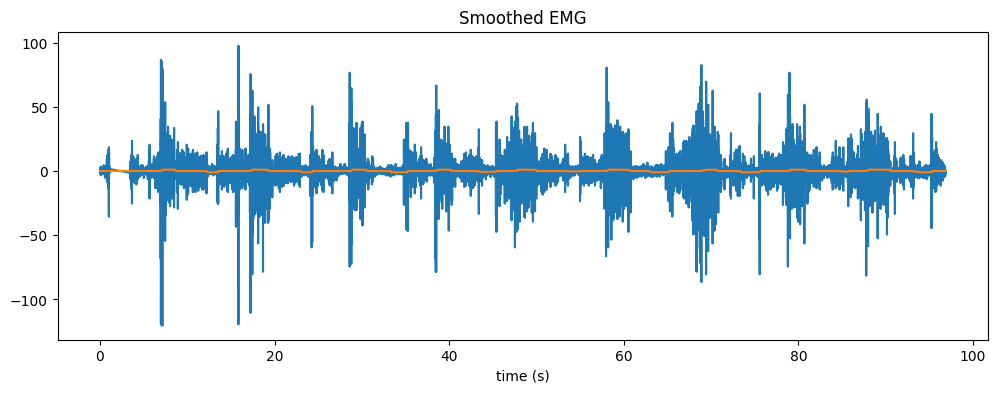

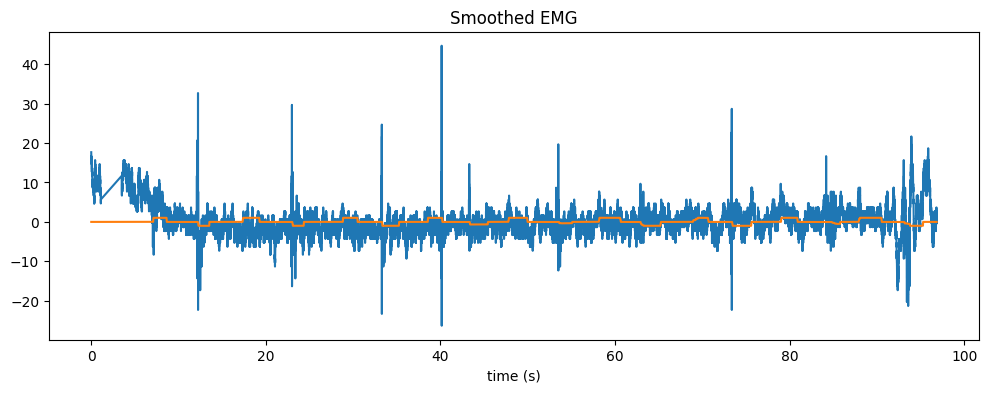

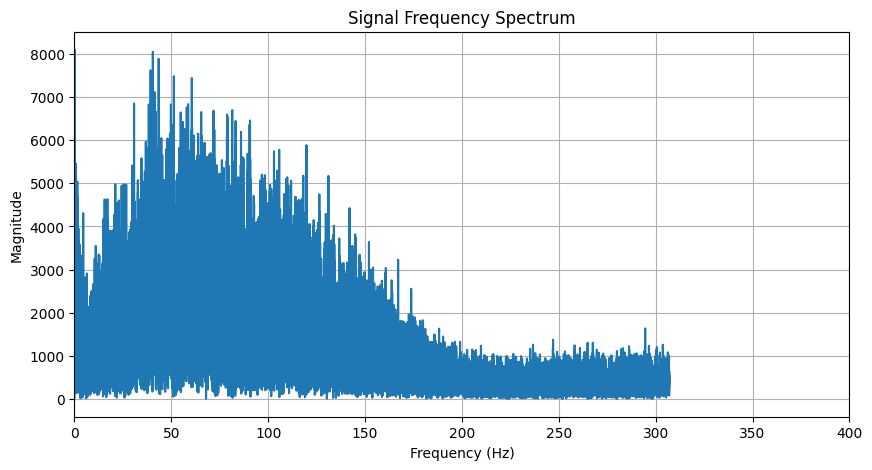

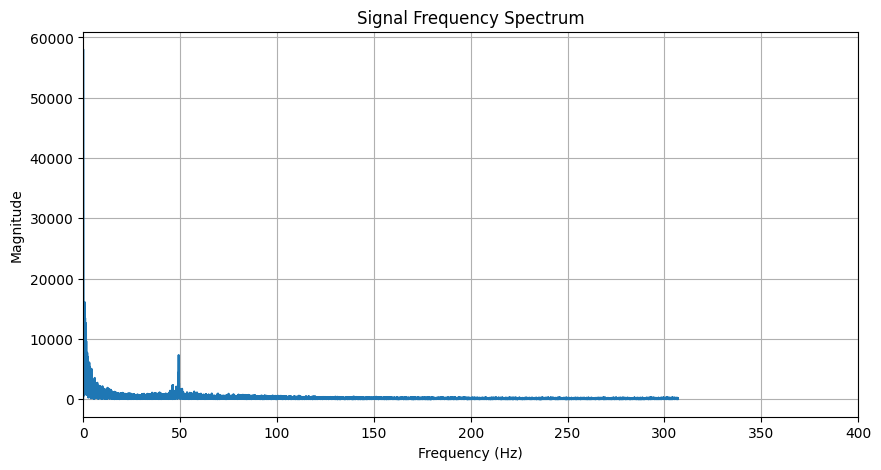

In [93]:
plot_emg_vs_joystick(df["t"], df["emg_ext"], df["y"]/500)
plot_emg_vs_joystick(df["t"], df["emg_flex"], df["y"]/500)
plot_frequencies(df["emg_ext"], fs, center=True)
plot_frequencies(df["emg_flex"], fs, center=True)

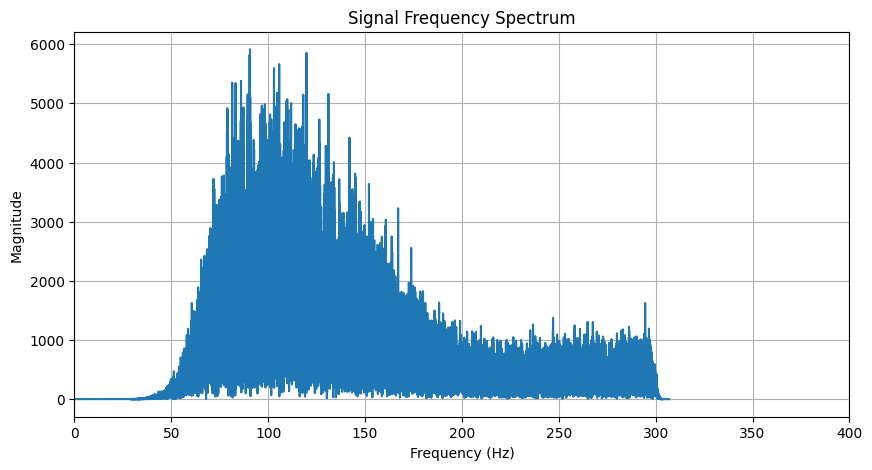

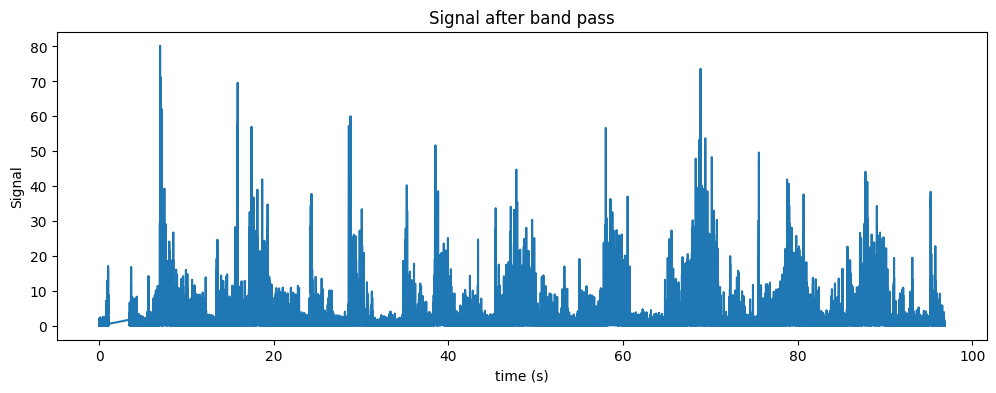

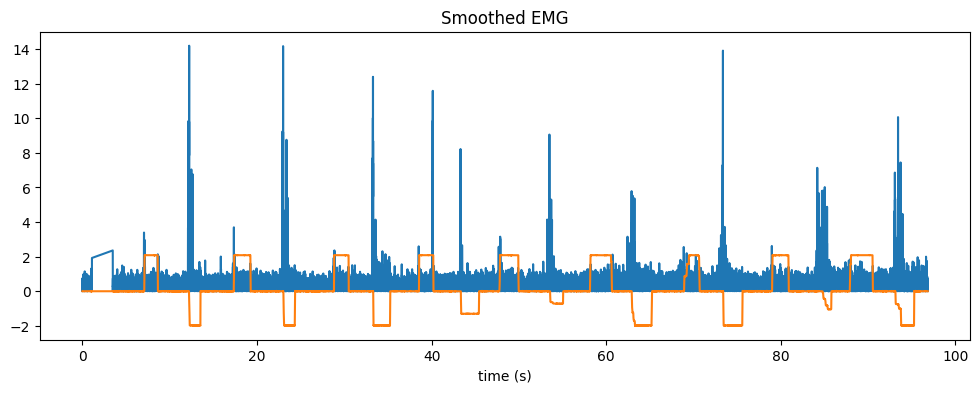

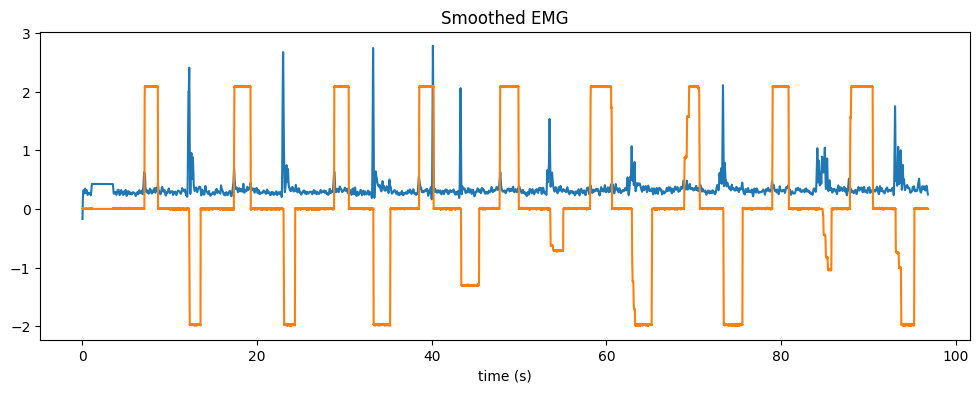

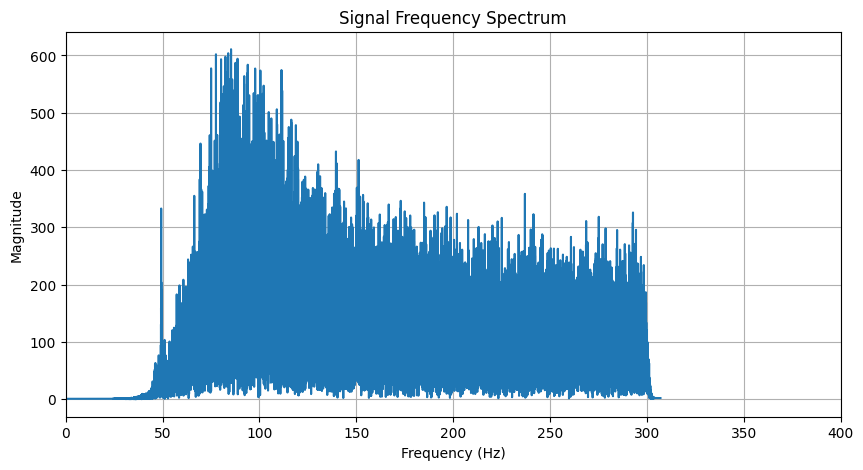

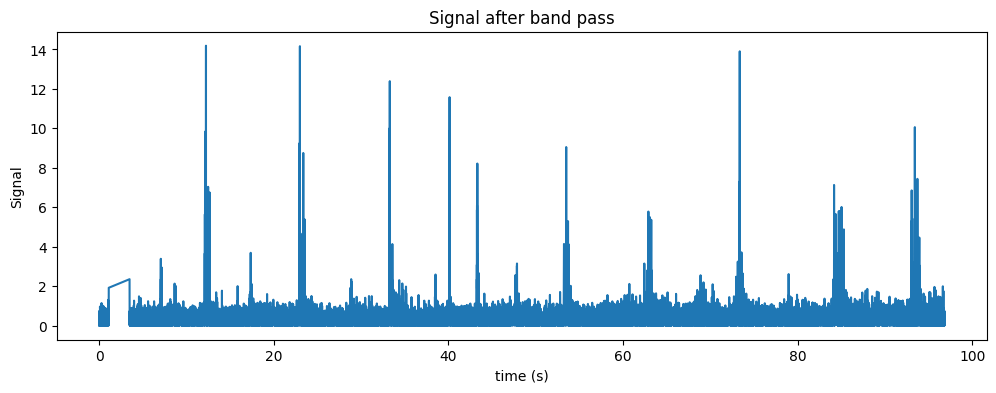

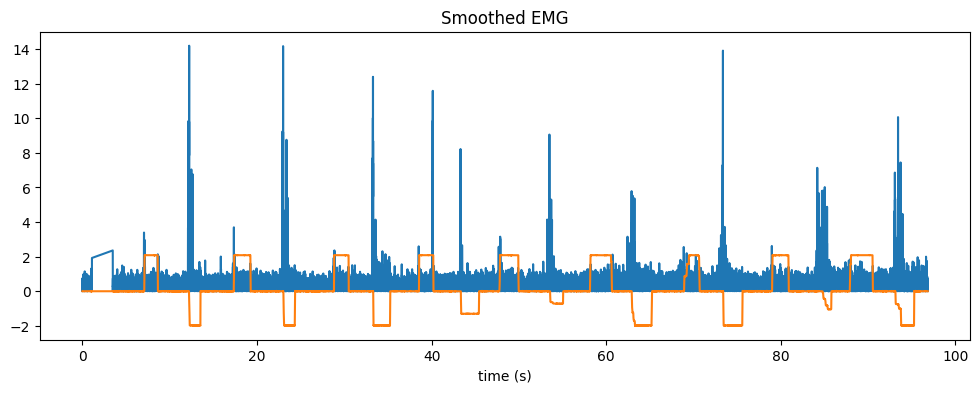

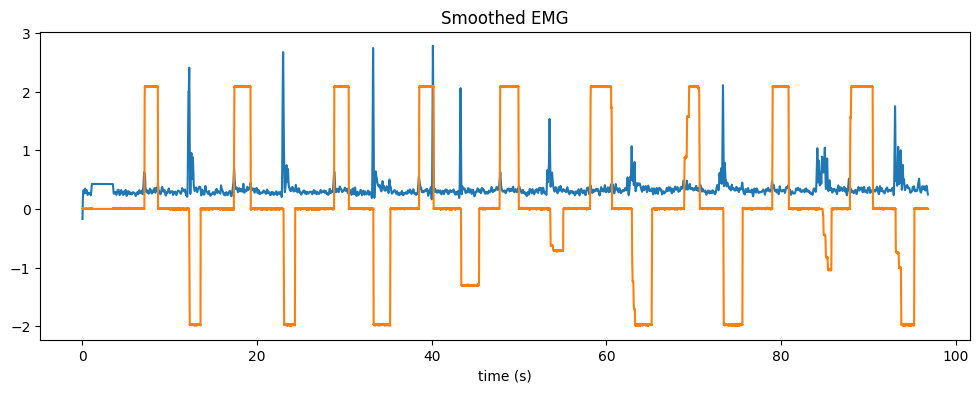

In [111]:
def apply_butter_pipeline(emg, low_pass_hz=1):
    low = 70
    high = 300
    
    b, a = signal.butter(
        N=4,
        Wn=[low, high],
        btype='bandpass',
        fs=fs
    )
    
    filtered = signal.filtfilt(b, a, emg)
    rectified = np.abs(filtered)

    # envelope: low-pass 5 Hz, por ejemplo
    b_lp, a_lp = signal.butter(2, low_pass_hz, btype="lowpass", fs=fs)
    envelope = signal.filtfilt(b_lp, a_lp, rectified)
    
    return filtered,  rectified, envelope

# Extensor digitorum   
emg_filt, emg_rect, emg_env = apply_butter_pipeline(df["emg_ext"])
df["emg_ext_env"] = emg_env

plot_frequencies(emg_filt, fs, center=True)
plot_signal(df["t"], emg_rect, "Signal after band pass")
plot_emg_vs_joystick(df["t"], rectified, df["y"]/250)
plot_emg_vs_joystick(df["t"], envelope, df["y"]/250)


# Flexor digitorum
emg_filt, emg_rect, emg_env = apply_butter_pipeline(df["emg_flex"])
df["emg_flex_env"] = emg_env


plot_frequencies(emg_filt, fs, center=True)
plot_signal(df["t"], emg_rect, "Signal after band pass")
plot_emg_vs_joystick(df["t"], rectified, df["y"]/250)
plot_emg_vs_joystick(df["t"], envelope, df["y"]/250)

0.6527775701190123


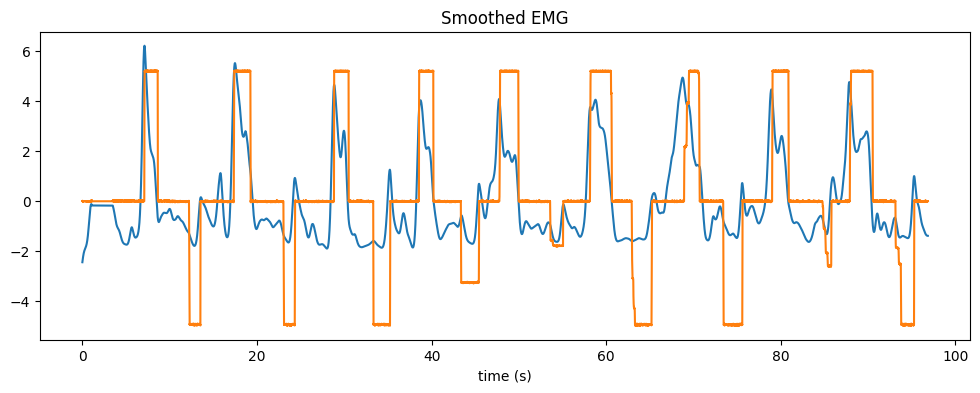

-0.18324849792746142


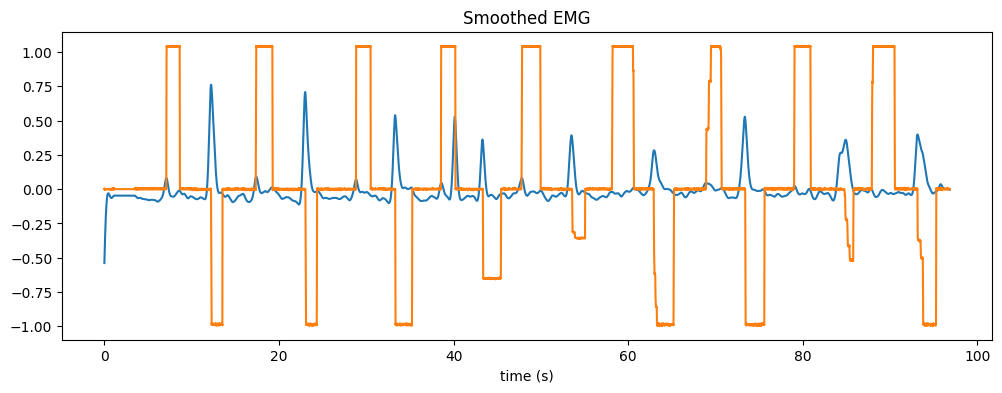

0.6430888335449079


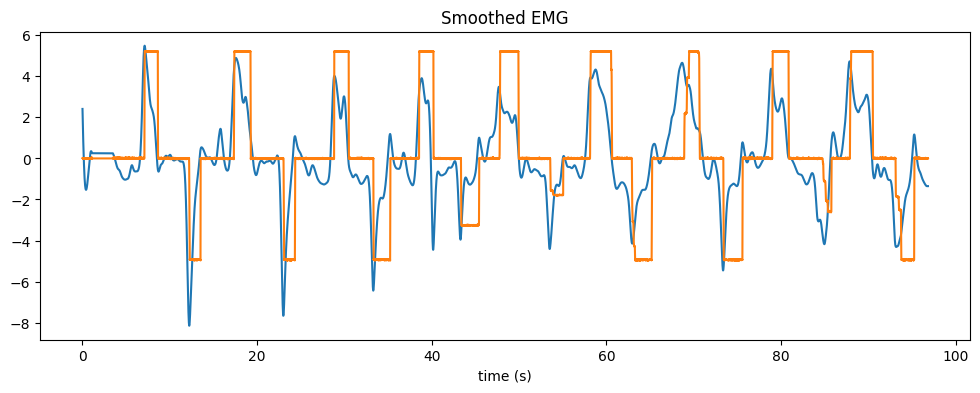

In [118]:
print(df["emg_ext_env"].corr(df["y"]))
plot_emg_vs_joystick(df["t"], df["emg_ext_env"]-df["emg_ext_env"].mean(), df["y"]/100)

print(df["emg_flex_env"].corr(df["y"]))
plot_emg_vs_joystick(df["t"], df["emg_flex_env"]-df["emg_flex_env"].mean(), df["y"]/500)

df["emg_env"] = (df["emg_ext_env"]-df["emg_ext_env"].mean()) - (df["emg_flex_env"]-df["emg_flex_env"].mean())*9
print(df["emg_env"].corr(df["y"]))
plot_emg_vs_joystick(df["t"], df["emg_env"], df["y"]/100)

In [117]:
def estimate_lag(a, b, fs):
    a = np.asarray(a) - np.mean(a)
    b = np.asarray(b) - np.mean(b)

    corr = np.correlate(a, b, mode="full")
    lags = np.arange(-len(a) + 1, len(a))

    best_lag_samples = lags[np.argmax(corr)]
    best_lag_seconds = best_lag_samples / fs

    return best_lag_samples, best_lag_seconds, corr

lag_samples, lag_seconds, corr = estimate_lag(df["emg_env"], df["y"], fs)

print("Lag samples:", lag_samples)
print("Lag seconds:", lag_seconds)

Lag samples: -250
Lag seconds: -0.40714970905788567


In [82]:
def best_shift(x, y, max_shift_samples=2000):
    """
    Busca el shift que maximiza correlación.

    shift > 0:
        x se mueve hacia adelante
    """

    x = np.asarray(x)
    y = np.asarray(y)

    x = (x - x.mean()) / x.std()
    y = (y - y.mean()) / y.std()

    best_corr = -np.inf
    best_shift = 0

    corrs = []
    shifts = range(-max_shift_samples, max_shift_samples)

    for shift in shifts:

        if shift > 0:
            x_shifted = x[shift:]
            y_cut = y[:-shift]

        elif shift < 0:
            x_shifted = x[:shift]
            y_cut = y[-shift:]

        else:
            x_shifted = x
            y_cut = y

        if len(x_shifted) < 100:
            continue

        corr = np.corrcoef(x_shifted, y_cut)[0, 1]

        corrs.append(corr)

        if corr > best_corr:
            best_corr = corr
            best_shift = shift

    return best_shift, best_corr, shifts, corrs

shift, corr, shifts, corrs = best_shift(
    df["emg_env"],
    df["y"],
    max_shift_samples=3000
)

print("Best shift:", shift)
print("Best corr:", corr)

Best shift: 2671
Best corr: 0.4231405267472691


In [83]:
emg = df["emg_env"].values
y = df["y"].values

if shift > 0:
    emg_aligned = emg[shift:]
    y_aligned = y[:-shift]
elif shift < 0:
    emg_aligned = emg[:shift]
    y_aligned = y[-shift:]
else:
    emg_aligned = emg
    y_aligned = y

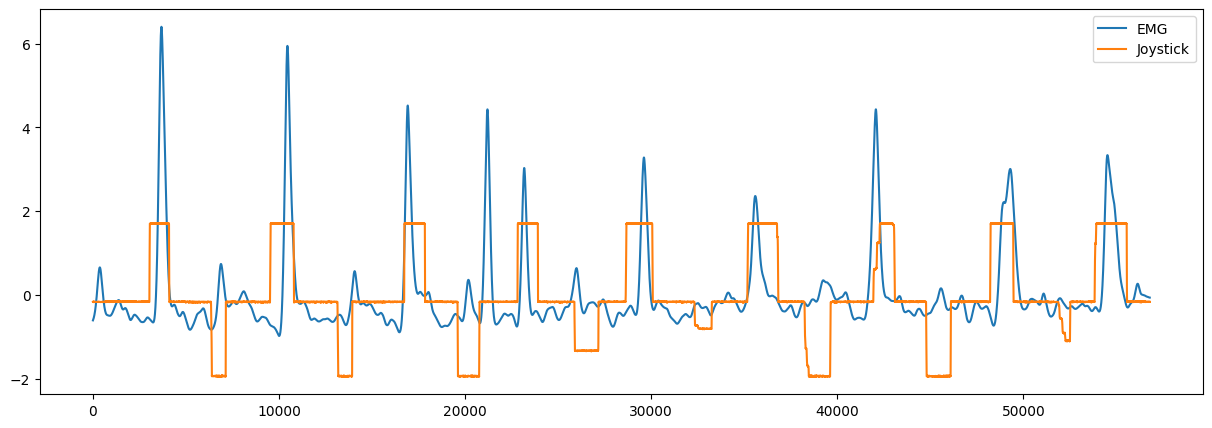

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))

plt.plot(
    (emg_aligned - np.mean(emg_aligned))/np.std(emg_aligned),
    label="EMG"
)

plt.plot(
    (y_aligned - np.mean(y_aligned))/np.std(y_aligned),
    label="Joystick"
)

plt.legend()
plt.show()